# 05 — Final Model Comparison

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

## 15. Final Model Comparison

In [ ]:
tuning_log_df = pd.read_csv(TUNING_LOG_PATH)
final_results_df = pd.read_csv(FINAL_RESULTS_PATH).sort_values('test_f1_macro', ascending=False).reset_index(drop=True)
final_results_df

,model,test_accuracy,test_f1_macro,test_f1_weighted
0,BERT-base,0.760168,0.760799,0.756636
1,GRU,0.759968,0.759888,0.755813
2,LogisticRegression,0.753872,0.756334,0.752240
3,BiGRU,0.758569,0.752487,0.748463
4,LSTM,0.751374,0.751200,0.746729
5,BiLSTM,0.752873,0.747246,0.744215
6,NaiveBayes,0.741181,0.739777,0.735899
7,RandomForest,0.723793,0.719141,0.712363
8,BiSimpleRNN,0.718197,0.713994,0.710147
9,SimpleRNN,0.576896,0.552686,0.549791


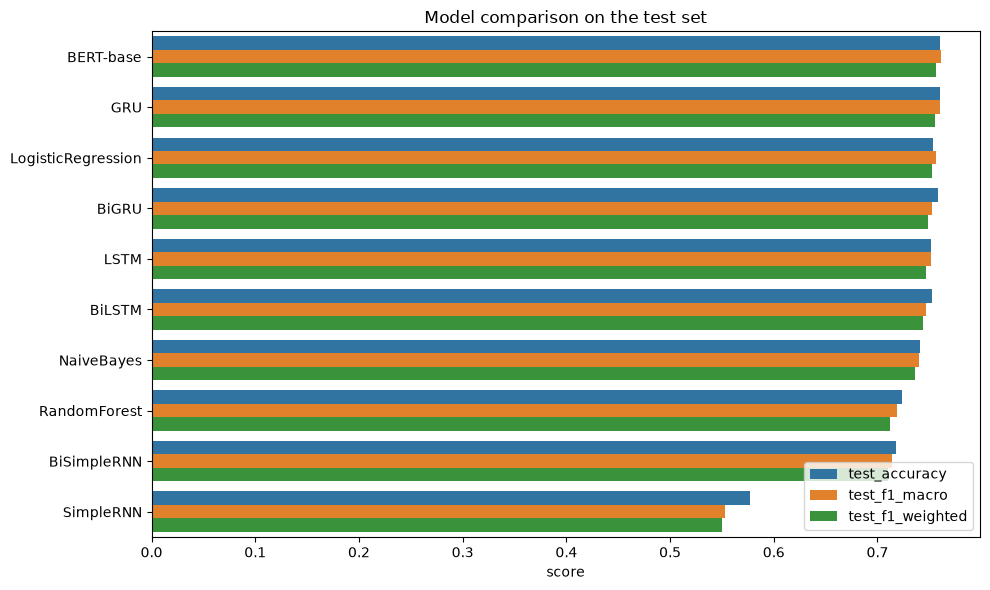

In [3]:
plt.figure(figsize=(10,6))
plot_df = final_results_df.melt(id_vars='model', value_vars=['test_accuracy', 'test_f1_macro', 'test_f1_weighted'],
                                 var_name='metric', value_name='score')
sns.barplot(data=plot_df, x='score', y='model', hue='metric')
plt.title('Model comparison on the test set')
plt.xlabel('score')
plt.ylabel('')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [4]:
best_model_row = final_results_df.iloc[0]
worst_model_row = final_results_df.iloc[-1]

print(f"Best-performing model:  {best_model_row['model']}  (test macro-F1 = {best_model_row['test_f1_macro']:.4f}, accuracy = {best_model_row['test_accuracy']:.4f})")
print(f"Worst-performing model: {worst_model_row['model']}  (test macro-F1 = {worst_model_row['test_f1_macro']:.4f}, accuracy = {worst_model_row['test_accuracy']:.4f})")

Best-performing model:  BERT-base  (test macro-F1 = 0.7608, accuracy = 0.7602)
Worst-performing model: SimpleRNN  (test macro-F1 = 0.5527, accuracy = 0.5769)


In [5]:
# Full hyperparameter tuning log (every config x every model, with validation metrics) -- for the report appendix.
tuning_log_df.sort_values(['model', 'val_f1_macro'], ascending=[True, False]).reset_index(drop=True)

,model,config,val_accuracy,val_f1_macro
0,BERT-base,"{'learning_rate': 5e-05, 'per_device_train_bat...",0.774935,0.776304
1,BERT-base,"{'learning_rate': 3e-05, 'per_device_train_bat...",0.771237,0.771780
2,BERT-base,"{'learning_rate': 2e-05, 'per_device_train_bat...",0.768139,0.769951
3,BiGRU,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.760544,0.754426
4,BiGRU,"{'units': 64, 'dropout': 0.2, 'learning_rate':...",0.754048,0.747651
5,BiGRU,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.754947,0.746161
6,BiLSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.759844,0.754209
7,BiLSTM,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.754048,0.747622
8,BiLSTM,"{'units': 64, 'dropout': 0.2, 'learning_rate':...",0.751849,0.747217
9,BiSimpleRNN,"{'units': 128, 'dropout': 0.3, 'learning_rate'...",0.715571,0.710138
